# LinearSVC baseline – SemEval-2025 Task 9: The Food Hazard Detection Challenge

Vlastné baseline riešenie s reprezentáciou TF-IDF a klasifikátorom **LinearSVC**. Notebook postupuje podľa krokov z návrhu baseline riešenia (kap. 2.2):

1. načítanie trénovacích a validačných dát,
2. výber textového vstupu a cieľových štítkov (`hazard-category`; kvôli porovnaniu s oficiálnym notebookom aj `product-category`, `hazard`, `product`),
3. vytvorenie reprezentácie textu pomocou TF-IDF,
4. natrénovanie LinearSVC,
5. predikcie na validačných dátach,
6. vyhodnotenie pomocou macro-F1 a ďalších metrík.

Nad rámec týchto krokov notebook obsahuje: porovnanie s oficiálnou konfiguráciou (TF-IDF + logistická regresia) v rovnakom experimente, bootstrap intervaly spoľahlivosti, kontrolný beh podľa protokolu oficiálneho notebooku (80/20 delenie trénovacích dát) a jedno záverečné vyhodnotenie na testovacej množine.

## Pravidlá reprodukovateľnosti

* Všetky náhodné prvky používajú jediný seed `SEED = 2024`: delenie dát, `LinearSVC(random_state=...)` a bootstrap (`np.random.default_rng(SEED)`).
* `LinearSVC` má explicitne nastavené `dual=True` a `max_iter=10000`, aby výsledok nezávisel od predvolených hodnôt konkrétnej verzie scikit-learn.
* TF-IDF vektorizátor sa učí **len z trénovacích dát** a je deterministický.
* Bootstrap používa tie isté vzorky pre všetky modely (párové porovnanie).
* Testovacia množina sa nepoužíva na žiadne rozhodnutie o modeli; vyhodnotí sa raz na konci.
* Verzie knižníc, kontrolné súčty dátových súborov a parametre modelov sa ukladajú do `results_linearsvc/run_info.json`.
* Rôzne verzie knižníc môžu dať mierne odlišné čísla (dokumentácia scikit-learn to pripúšťa), preto sa pri porovnaní výsledkov porovnáva `run_info.json`.

## Požiadavky

Python 3.12, knižnice `pandas`, `numpy`, `scikit-learn`, `matplotlib`, `jupyterlab`. V priečinku `data/` vedľa notebooku musia byť súbory `incidents_train.csv`, `incidents_valid.csv` a `incidents_test.csv` z repozitára úlohy.

## 0. Importy a nastavenie seedu

In [1]:
import hashlib
import json
import platform
import random
import sys
import warnings
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.svm import LinearSVC

SEED = 2024
random.seed(SEED)
np.random.seed(SEED)

ENV_INFO = {
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit-learn": sklearn.__version__,
    "matplotlib": matplotlib.__version__,
    "seed": SEED,
}
print(json.dumps(ENV_INFO, indent=2))

{
  "python": "3.12.14",
  "platform": "Windows-11-10.0.26200-SP0",
  "numpy": "2.5.2",
  "pandas": "3.0.6",
  "scikit-learn": "1.9.1",
  "matplotlib": "3.11.2",
  "seed": 2024
}


In [2]:
# ---- Konfigurácia experimentu ----
DATA_DIR = Path("data")
OUT_DIR = Path("results_linearsvc")
OUT_DIR.mkdir(exist_ok=True)

FILES = {"train": "incidents_train.csv", "valid": "incidents_valid.csv", "test": "incidents_test.csv"}
TEXT_COL = "title"
LABELS = ["hazard-category", "product-category", "hazard", "product"]
SUBTASKS = {  # podúloha -> (štítok nebezpečenstva, štítok produktu)
    "S podúloha 1": ("hazard-category", "product-category"),
    "S podúloha 2": ("hazard", "product"),
}

SPLIT_SEED = SEED          # delenie pre kontrolný beh podľa oficiálneho notebooku
N_BOOT = 500               # počet bootstrap opakovaní
RUN_LR_REFERENCE = True    # logistická regresia v oficiálnej konfigurácii (referencia)
RUN_OFFICIAL_PROTOCOL = True  # kontrolný beh: 80/20 delenie trénovacích dát

PRIMARY = "LinearSVC"
REFERENCE = "LogReg (oficiálny baseline)"

# Hodnoty z oficiálnych zdrojov, len na porovnanie (nepoužívajú sa pri tréningu):
OFFICIAL_NOTEBOOK_DEV = {"S podúloha 1": 0.449, "S podúloha 2": 0.121}   # výstup oficiálneho notebooku
OFFICIAL_BASELINE_TEST = {"S podúloha 1": 0.498, "S podúloha 2": 0.183}  # Randl et al. (2025), TF-IDF + LR

## 1. Načítanie trénovacích a validačných dát

Súbory sa načítajú rovnako ako v oficiálnom notebooku (`index_col=0`). Overuje sa prítomnosť potrebných stĺpcov a chýbajúcich hodnôt a vypisuje sa SHA-256 každého súboru, aby bolo možné overiť, že ďalší používateľ pracuje s rovnakými dátami.

In [3]:
def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


missing = [name for name in FILES.values() if not (DATA_DIR / name).exists()]
if missing:
    raise FileNotFoundError(
        f"V priečinku '{DATA_DIR}' chýbajú súbory: {missing}. "
        "Skopírujte priečinok data/ z repozitára úlohy vedľa tohto notebooku."
    )

datasets = {name: pd.read_csv(DATA_DIR / fname, index_col=0) for name, fname in FILES.items()}
data_hashes = {name: sha256(DATA_DIR / fname) for name, fname in FILES.items()}

for name, df in datasets.items():
    absent = [c for c in [TEXT_COL] + LABELS if c not in df.columns]
    assert not absent, f"{name}: chýbajú stĺpce {absent}"
    assert not df[LABELS].isna().any().any(), f"{name}: chýbajúce hodnoty v štítkoch"
    n_na = int(df[TEXT_COL].isna().sum())
    df[TEXT_COL] = df[TEXT_COL].fillna("").astype(str)
    print(f"{name:5s} riadkov: {len(df):5d} | prázdnych titulkov: {n_na} | sha256: {data_hashes[name][:16]}...")

train_df, valid_df, test_df = datasets["train"], datasets["valid"], datasets["test"]

print("\nTitulky z valid, ktoré sa nachádzajú aj v train:", valid_df[TEXT_COL].isin(set(train_df[TEXT_COL])).sum())
print("Titulky z test, ktoré sa nachádzajú aj v train: ", test_df[TEXT_COL].isin(set(train_df[TEXT_COL])).sum())
display(train_df[[TEXT_COL] + LABELS].head(3))

train riadkov:  5082 | prázdnych titulkov: 0 | sha256: e1309f1d6d68b904...
valid riadkov:   565 | prázdnych titulkov: 0 | sha256: 80dc04c1d9b0024d...
test  riadkov:   997 | prázdnych titulkov: 0 | sha256: 3dd8102b0031cd27...

Titulky z valid, ktoré sa nachádzajú aj v train: 25
Titulky z test, ktoré sa nachádzajú aj v train:  43


,title,hazard-category,product-category,hazard,product
0,Recall Notification: FSIS-024-94,biological,"meat, egg and dairy products",listeria monocytogenes,smoked sausage
1,Recall Notification: FSIS-033-94,biological,"meat, egg and dairy products",listeria spp,sausage
2,Recall Notification: FSIS-014-94,biological,"meat, egg and dairy products",listeria monocytogenes,ham slices


## 2. Textový vstup a cieľové štítky

Ako vstup sa používa stĺpec `title` (rovnako ako v oficiálnom notebooku). Hlavným cieľom podľa návrhu je `hazard-category`; trénujú sa však všetky štyri štítky, aby bolo možné vypočítať oficiálne skóre pre obe podúlohy. Tabuľka ukazuje počet tried a koľko tried z validačnej a testovacej množiny sa v trénovacej množine vôbec nevyskytuje (takéto triedy nemožno správne predpovedať).

In [4]:
overview = {}
for label in LABELS:
    train_classes = set(train_df[label])
    overview[label] = {
        "tried v train": len(train_classes),
        "tried vo valid": valid_df[label].nunique(),
        "tried vo valid, ktoré nie sú v train": len(set(valid_df[label]) - train_classes),
        "tried v test": test_df[label].nunique(),
        "tried v test, ktoré nie sú v train": len(set(test_df[label]) - train_classes),
    }
display(pd.DataFrame(overview).T)
display(train_df["hazard-category"].value_counts().to_frame("počet v train"))

,tried v train,tried vo valid,"tried vo valid, ktoré nie sú v train",tried v test,"tried v test, ktoré nie sú v train"
hazard-category,10,9,0,10,0
product-category,22,18,0,20,0
hazard,128,93,0,110,0
product,1022,312,46,447,82


,počet v train
hazard-category,
allergens,1854
biological,1741
foreign bodies,561
fraud,371
chemical,287
other hazard,134
packaging defect,54
organoleptic aspects,53
food additives and flavourings,24


## 3. TF-IDF reprezentácia, modely a metriky

* **TF-IDF**: rovnaké nastavenie ako v oficiálnom notebooku (znakové n-gramy 2–5, `max_df=0.5`, `min_df=5`), aby sa porovnával klasifikátor, nie reprezentácia.
* **LinearSVC** (`C=1.0`): hlavný model.
* **LinearSVC s `class_weight='balanced'`**: variant, ktorý zvyšuje váhu zriedkavých tried.
* **LogReg (oficiálny baseline)**: referencia, rovnaké parametre ako v oficiálnom notebooku.

Metriky: macro-F1, micro-F1 a oficiálne kombinované skóre $S$ (hazard + produkt pre správne určené nebezpečenstvá). Všetky volania `f1_score` používajú `zero_division=0`.

In [5]:
def make_vectorizer():
    return TfidfVectorizer(strip_accents="unicode", analyzer="char", ngram_range=(2, 5), max_df=0.5, min_df=5)


def make_models():
    models = {
        PRIMARY: lambda: LinearSVC(C=1.0, dual=True, max_iter=10000, random_state=SEED),
        "LinearSVC (class_weight=balanced)": lambda: LinearSVC(
            C=1.0, class_weight="balanced", dual=True, max_iter=10000, random_state=SEED
        ),
    }
    if RUN_LR_REFERENCE:
        # oficiálne parametre; random_state nemá vplyv na solver lbfgs, nastavuje sa len pre úplnosť
        models[REFERENCE] = lambda: LogisticRegression(max_iter=1000, random_state=SEED)
    return models


def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro", zero_division=0)


def micro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average="micro", zero_division=0)


def compute_score(h_true, p_true, h_pred, p_pred):
    """Oficiálne skóre súťaže; produkt sa hodnotí len tam, kde je nebezpečenstvo určené správne."""
    h_true, p_true, h_pred, p_pred = (np.asarray(a) for a in (h_true, p_true, h_pred, p_pred))
    f1_h = macro_f1(h_true, h_pred)
    ok = h_true == h_pred
    f1_p = macro_f1(p_true[ok], p_pred[ok]) if ok.any() else 0.0
    return (f1_h + f1_p) / 2.0


MODELS = make_models()
print("Modely:", list(MODELS))
for name, factory in MODELS.items():
    print(f"  {name}: {factory()!r}")

Modely: ['LinearSVC', 'LinearSVC (class_weight=balanced)', 'LogReg (oficiálny baseline)']
  LinearSVC: LinearSVC(dual=True, max_iter=10000, random_state=2024)
  LinearSVC (class_weight=balanced): LinearSVC(class_weight='balanced', dual=True, max_iter=10000, random_state=2024)
  LogReg (oficiálny baseline): LogisticRegression(max_iter=1000, random_state=2024)


## 4.–5. Tréning a predikcie

Pre každý model a každý štítok sa model trénuje len na trénovacej množine. Vektorizátor sa učí raz z trénovacích titulkov (nezávisí od štítku). Počíta sa aj počet `ConvergenceWarning`; nenulová hodnota znamená, že optimalizácia nekonvergovala a výsledok môže byť citlivejší na verziu knižnice. Predikcie testovacej množiny sa tu len uložia; vyhodnotia sa až v sekcii 8.

In [6]:
def fit_and_predict(train_data, eval_sets, factories):
    vec = make_vectorizer()
    X_train = vec.fit_transform(train_data[TEXT_COL])
    X_eval = {name: vec.transform(df[TEXT_COL]) for name, df in eval_sets.items()}
    print(f"TF-IDF: {X_train.shape[0]} dokumentov, {X_train.shape[1]} príznakov")

    preds, conv = {}, {}
    for m_name, factory in factories.items():
        preds[m_name] = {n: {} for n in eval_sets}
        conv[m_name] = {}
        for label in LABELS:
            model = factory()
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter("always")
                model.fit(X_train, train_data[label])
            conv[m_name][label] = sum(issubclass(w.category, ConvergenceWarning) for w in caught)
            for n, X in X_eval.items():
                preds[m_name][n][label] = model.predict(X)
            print(f"  hotovo: {m_name} | {label}")
    return vec, preds, conv


eval_sets = {"valid": valid_df, "test": test_df}
vectorizer, preds, conv = fit_and_predict(train_df, eval_sets, MODELS)

TF-IDF: 5082 dokumentov, 25260 príznakov
  hotovo: LinearSVC | hazard-category
  hotovo: LinearSVC | product-category
  hotovo: LinearSVC | hazard
  hotovo: LinearSVC | product
  hotovo: LinearSVC (class_weight=balanced) | hazard-category
  hotovo: LinearSVC (class_weight=balanced) | product-category
  hotovo: LinearSVC (class_weight=balanced) | hazard
  hotovo: LinearSVC (class_weight=balanced) | product
  hotovo: LogReg (oficiálny baseline) | hazard-category
  hotovo: LogReg (oficiálny baseline) | product-category
  hotovo: LogReg (oficiálny baseline) | hazard
  hotovo: LogReg (oficiálny baseline) | product


## 6. Vyhodnotenie na validačnej množine

In [7]:
def evaluate(eval_df, model_preds):
    rows = {}
    for m_name, p in model_preds.items():
        r = {}
        for label in LABELS:
            y = eval_df[label].to_numpy()
            r[f"{label} (macro-F1)"] = macro_f1(y, p[label])
            r[f"{label} (micro-F1)"] = micro_f1(y, p[label])
        for st, (h, pr) in SUBTASKS.items():
            r[st] = compute_score(eval_df[h].to_numpy(), eval_df[pr].to_numpy(), p[h], p[pr])
        rows[m_name] = r
    return pd.DataFrame(rows)


valid_scores = evaluate(valid_df, {m: preds[m]["valid"] for m in preds})
print("Validačná množina (výsledky sú zaokrúhlené na 3 desatinné miesta):")
display(valid_scores.round(3))

conv_table = pd.DataFrame(conv).T
print("Počet ConvergenceWarning pri tréningu (0 = optimalizácia konvergovala):")
display(conv_table)

Validačná množina (výsledky sú zaokrúhlené na 3 desatinné miesta):


,LinearSVC,LinearSVC (class_weight=balanced),LogReg (oficiálny baseline)
hazard-category (macro-F1),0.663,0.679,0.515
hazard-category (micro-F1),0.835,0.821,0.807
product-category (macro-F1),0.646,0.727,0.465
product-category (micro-F1),0.740,0.742,0.648
hazard (macro-F1),0.475,0.410,0.200
hazard (micro-F1),0.658,0.627,0.581
product (macro-F1),0.281,0.232,0.122
product (micro-F1),0.488,0.427,0.313
S podúloha 1,0.678,0.694,0.498
S podúloha 2,0.409,0.355,0.183


Počet ConvergenceWarning pri tréningu (0 = optimalizácia konvergovala):


,hazard-category,product-category,hazard,product
LinearSVC,0,0,0,0
LinearSVC (class_weight=balanced),0,0,0,0
LogReg (oficiálny baseline),0,0,0,0


### Intervaly spoľahlivosti (bootstrap)

Validačná množina má len stovky vzoriek a mnoho tried má málo príkladov, preto je macro-F1 a skóre $S$ šumové. Bootstrap (percentilový 95 % interval) pre skóre $S$ používa pevný generátor (`default_rng(SEED)`) a **rovnaké vzorky pre všetky modely**, takže rozdiely medzi modelmi sú párové.

In [8]:
def bootstrap_draws(eval_df, model_preds, n_boot, seed):
    enc = {}
    for label in LABELS:
        vals = [eval_df[label].to_numpy()] + [p[label] for p in model_preds.values()]
        enc[label] = LabelEncoder().fit(np.concatenate(vals))
    y_true = {l: enc[l].transform(eval_df[l].to_numpy()) for l in LABELS}
    y_pred = {m: {l: enc[l].transform(p[l]) for l in LABELS} for m, p in model_preds.items()}

    rng = np.random.default_rng(seed)
    n = len(eval_df)
    idx = rng.integers(0, n, size=(n_boot, n))
    draws = {m: {st: np.empty(n_boot) for st in SUBTASKS} for m in model_preds}
    for b in range(n_boot):
        ix = idx[b]
        for m in model_preds:
            for st, (h, pr) in SUBTASKS.items():
                draws[m][st][b] = compute_score(y_true[h][ix], y_true[pr][ix], y_pred[m][h][ix], y_pred[m][pr][ix])
    return draws


def summarize_draws(draws, point_scores):
    rows = []
    for m in draws:
        for st in SUBTASKS:
            lo, hi = np.percentile(draws[m][st], [2.5, 97.5])
            rows.append({"model": m, "metrika": st, "hodnota": point_scores.loc[st, m],
                         "95 % CI od": lo, "95 % CI do": hi})
    return pd.DataFrame(rows)


def paired_difference(draws, a, b):
    rows = []
    for st in SUBTASKS:
        d = draws[a][st] - draws[b][st]
        lo, hi = np.percentile(d, [2.5, 97.5])
        rows.append({"metrika": st, "priemerný rozdiel": d.mean(), "95 % CI od": lo, "95 % CI do": hi,
                     f"podiel pokusov, kde {a} > {b}": float((d > 0).mean())})
    return pd.DataFrame(rows)


draws_valid = bootstrap_draws(valid_df, {m: preds[m]["valid"] for m in preds}, N_BOOT, SEED)
ci_valid = summarize_draws(draws_valid, valid_scores)
display(ci_valid.round(3))
if REFERENCE in draws_valid:
    print(f"Párový rozdiel {PRIMARY} - {REFERENCE} (validačná množina):")
    display(paired_difference(draws_valid, PRIMARY, REFERENCE).round(3))

,model,metrika,hodnota,95 % CI od,95 % CI do
0,LinearSVC,S podúloha 1,0.678,0.595,0.726
1,LinearSVC,S podúloha 2,0.409,0.373,0.448
2,LinearSVC (class_weight=balanced),S podúloha 1,0.694,0.618,0.746
3,LinearSVC (class_weight=balanced),S podúloha 2,0.355,0.316,0.382
4,LogReg (oficiálny baseline),S podúloha 1,0.498,0.454,0.564
5,LogReg (oficiálny baseline),S podúloha 2,0.183,0.187,0.234


Párový rozdiel LinearSVC - LogReg (oficiálny baseline) (validačná množina):


,metrika,priemerný rozdiel,95 % CI od,95 % CI do,"podiel pokusov, kde LinearSVC > LogReg (oficiálny baseline)"
0,S podúloha 1,0.159,0.089,0.233,1.0
1,S podúloha 2,0.202,0.165,0.238,1.0


### Detailná analýza cieľového štítku `hazard-category`

Podrobný report po triedach a matica zámen (normalizovaná po riadkoch) pre hlavný model.

                                precision    recall  f1-score   support

                     allergens      0.837     0.918     0.876       207
                    biological      0.883     0.933     0.907       194
                      chemical      0.800     0.571     0.667        28
food additives and flavourings      1.000     0.500     0.667         2
                foreign bodies      0.783     0.746     0.764        63
                         fraud      0.703     0.634     0.667        41
          organoleptic aspects      1.000     0.625     0.769         8
                  other hazard      0.625     0.357     0.455        14
              packaging defect      0.500     0.125     0.200         8

                      accuracy                          0.835       565
                     macro avg      0.792     0.601     0.663       565
                  weighted avg      0.828     0.835     0.826       565



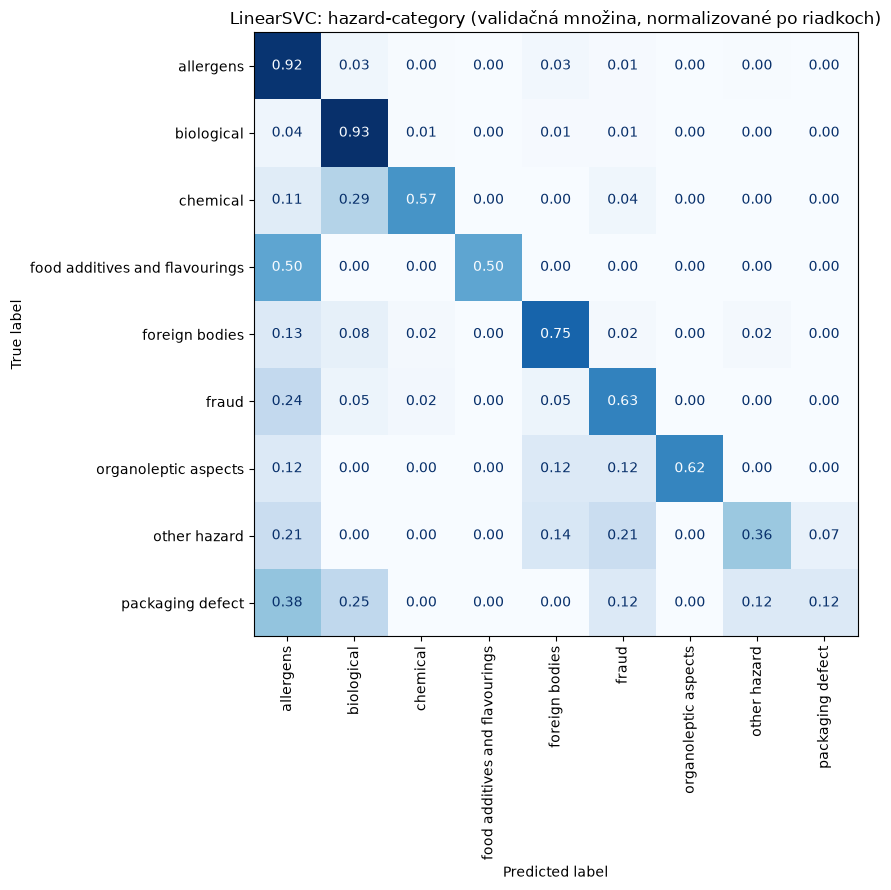

In [9]:
label = "hazard-category"
y_v = valid_df[label].to_numpy()
p_v = preds[PRIMARY]["valid"][label]

print(classification_report(y_v, p_v, digits=3, zero_division=0))

fig, ax = plt.subplots(figsize=(10, 9))
ConfusionMatrixDisplay.from_predictions(
    y_v, p_v, normalize="true", xticks_rotation="vertical", values_format=".2f",
    cmap="Blues", ax=ax, colorbar=False,
)
ax.set_title(f"{PRIMARY}: {label} (validačná množina, normalizované po riadkoch)")
fig.tight_layout()
fig.savefig(OUT_DIR / "confusion_hazard_category_valid.png", dpi=150)
plt.show()

### Pokrytie tried

Koľko tried má F1 rovné 0. Pri štítkoch `hazard` a `product` s množstvom tried ide o hlavný dôvod nízkeho macro-F1.

In [10]:
def class_coverage(eval_df, pred, label):
    y = eval_df[label].to_numpy()
    classes = np.unique(np.concatenate([y, pred]))
    f1s = f1_score(y, pred, labels=classes, average=None, zero_division=0)
    support = pd.Series(y).value_counts().reindex(classes).fillna(0).astype(int).to_numpy()
    return {
        "tried (zjednotenie y_true a y_pred)": len(classes),
        "tried s podporou > 0": int((support > 0).sum()),
        "tried s podporou > 0 a F1 = 0": int(((f1s == 0) & (support > 0)).sum()),
        "tried len v predikciách (F1 = 0)": int((support == 0).sum()),
    }


coverage = {l: class_coverage(valid_df, preds[PRIMARY]["valid"][l], l) for l in LABELS}
display(pd.DataFrame(coverage).T)

,tried (zjednotenie y_true a y_pred),tried s podporou > 0,tried s podporou > 0 a F1 = 0,tried len v predikciách (F1 = 0)
hazard-category,9,9,0,0
product-category,18,18,1,0
hazard,93,93,33,0
product,384,312,176,72


## 7. Kontrolný beh podľa protokolu oficiálneho notebooku

Oficiálny notebook vyhodnocuje na náhodných 20 % trénovacích dát (`train_test_split(test_size=0.2, random_state=2024)`). Tu sa rovnaký protokol zopakuje pre všetky modely, aby bolo možné priamo porovnať s oficiálnymi hodnotami 0,449 a 0,121. Rozdiel pre referenčný model by sa mal blížiť nule; ak nie, ide pravdepodobne o odlišné verzie knižníc alebo dát.

In [11]:
if RUN_OFFICIAL_PROTOCOL:
    sub_train, sub_dev = train_test_split(train_df, test_size=0.2, random_state=SPLIT_SEED)
    print(f"sub_train: {len(sub_train)}, sub_dev: {len(sub_dev)}")
    _, preds_off, conv_off = fit_and_predict(sub_train, {"dev20": sub_dev}, MODELS)
    off_scores = evaluate(sub_dev, {m: preds_off[m]["dev20"] for m in preds_off})
    display(off_scores.round(3))
    print("Počet ConvergenceWarning:")
    display(pd.DataFrame(conv_off).T)

    if REFERENCE in off_scores.columns:
        cmp = pd.DataFrame({
            "oficiálny notebook (výstup)": OFFICIAL_NOTEBOOK_DEV,
            f"tento notebook: {REFERENCE}": {st: off_scores.loc[st, REFERENCE] for st in SUBTASKS},
        })
        cmp["rozdiel"] = cmp.iloc[:, 1] - cmp.iloc[:, 0]
        display(cmp.round(3))
else:
    off_scores = None

sub_train: 4065, sub_dev: 1017
TF-IDF: 4065 dokumentov, 21645 príznakov
  hotovo: LinearSVC | hazard-category
  hotovo: LinearSVC | product-category
  hotovo: LinearSVC | hazard
  hotovo: LinearSVC | product
  hotovo: LinearSVC (class_weight=balanced) | hazard-category
  hotovo: LinearSVC (class_weight=balanced) | product-category
  hotovo: LinearSVC (class_weight=balanced) | hazard
  hotovo: LinearSVC (class_weight=balanced) | product
  hotovo: LogReg (oficiálny baseline) | hazard-category
  hotovo: LogReg (oficiálny baseline) | product-category
  hotovo: LogReg (oficiálny baseline) | hazard
  hotovo: LogReg (oficiálny baseline) | product


,LinearSVC,LinearSVC (class_weight=balanced),LogReg (oficiálny baseline)
hazard-category (macro-F1),0.692,0.654,0.458
hazard-category (micro-F1),0.844,0.836,0.810
product-category (macro-F1),0.565,0.538,0.394
product-category (micro-F1),0.726,0.714,0.658
hazard (macro-F1),0.339,0.347,0.139
hazard (micro-F1),0.641,0.606,0.537
product (macro-F1),0.233,0.187,0.072
product (micro-F1),0.463,0.399,0.273
S podúloha 1,0.636,0.595,0.449
S podúloha 2,0.310,0.287,0.121


Počet ConvergenceWarning:


,hazard-category,product-category,hazard,product
LinearSVC,0,0,0,0
LinearSVC (class_weight=balanced),0,0,0,0
LogReg (oficiálny baseline),0,0,0,0


,oficiálny notebook (výstup),tento notebook: LogReg (oficiálny baseline),rozdiel
S podúloha 1,0.449,0.449,0.0
S podúloha 2,0.121,0.121,-0.0


## 8. Záverečné vyhodnotenie na testovacej množine

Modely boli natrénované len na trénovacej množine a žiadne rozhodnutie nebolo urobené na základe testovacej množiny. Hodnota „oficiálny baseline" pochádza z článku organizátorov (Randl et al., 2025) a nejde o beh v tomto notebooku.

In [12]:
test_scores = evaluate(test_df, {m: preds[m]["test"] for m in preds})
display(test_scores.round(3))

summary_test = test_scores.loc[list(SUBTASKS)].T
summary_test.loc["oficiálny baseline TF-IDF + LR (Randl et al., 2025)"] = pd.Series(OFFICIAL_BASELINE_TEST)
display(summary_test.round(3))

draws_test = bootstrap_draws(test_df, {m: preds[m]["test"] for m in preds}, N_BOOT, SEED)
ci_test = summarize_draws(draws_test, test_scores)
display(ci_test.round(3))
if REFERENCE in draws_test:
    print(f"Párový rozdiel {PRIMARY} - {REFERENCE} (testovacia množina):")
    display(paired_difference(draws_test, PRIMARY, REFERENCE).round(3))

,LinearSVC,LinearSVC (class_weight=balanced),LogReg (oficiálny baseline)
hazard-category (macro-F1),0.648,0.620,0.508
hazard-category (micro-F1),0.861,0.852,0.828
product-category (macro-F1),0.700,0.683,0.452
product-category (micro-F1),0.782,0.767,0.702
hazard (macro-F1),0.428,0.425,0.154
hazard (micro-F1),0.655,0.618,0.552
product (macro-F1),0.275,0.240,0.081
product (micro-F1),0.497,0.447,0.299
S podúloha 1,0.674,0.657,0.483
S podúloha 2,0.375,0.351,0.129


,S podúloha 1,S podúloha 2
LinearSVC,0.674,0.375
LinearSVC (class_weight=balanced),0.657,0.351
LogReg (oficiálny baseline),0.483,0.129
"oficiálny baseline TF-IDF + LR (Randl et al., 2025)",0.498,0.183


,model,metrika,hodnota,95 % CI od,95 % CI do
0,LinearSVC,S podúloha 1,0.674,0.624,0.744
1,LinearSVC,S podúloha 2,0.375,0.349,0.407
2,LinearSVC (class_weight=balanced),S podúloha 1,0.657,0.613,0.725
3,LinearSVC (class_weight=balanced),S podúloha 2,0.351,0.320,0.371
4,LogReg (oficiálny baseline),S podúloha 1,0.483,0.451,0.561
5,LogReg (oficiálny baseline),S podúloha 2,0.129,0.136,0.166


Párový rozdiel LinearSVC - LogReg (oficiálny baseline) (testovacia množina):


,metrika,priemerný rozdiel,95 % CI od,95 % CI do,"podiel pokusov, kde LinearSVC > LogReg (oficiálny baseline)"
0,S podúloha 1,0.184,0.126,0.237,1.0
1,S podúloha 2,0.226,0.196,0.257,1.0


## 9. Uloženie výsledkov

In [13]:
valid_scores.to_csv(OUT_DIR / "scores_valid.csv", float_format="%.6f")
test_scores.to_csv(OUT_DIR / "scores_test.csv", float_format="%.6f")
ci_valid.to_csv(OUT_DIR / "bootstrap_valid.csv", index=False, float_format="%.6f")
ci_test.to_csv(OUT_DIR / "bootstrap_test.csv", index=False, float_format="%.6f")
conv_table.to_csv(OUT_DIR / "convergence_warnings.csv")
if off_scores is not None:
    off_scores.to_csv(OUT_DIR / "scores_official_protocol.csv", float_format="%.6f")

for name, df in eval_sets.items():
    out = pd.DataFrame({l: preds[PRIMARY][name][l] for l in LABELS}, index=df.index)
    out.to_csv(OUT_DIR / f"predictions_{name}_{PRIMARY.lower()}.csv")

run_info = {
    "environment": ENV_INFO,
    "data_sha256": data_hashes,
    "tfidf": repr(make_vectorizer()),
    "models": {name: repr(factory()) for name, factory in MODELS.items()},
    "n_boot": N_BOOT,
    "split_seed": SPLIT_SEED,
}
with open(OUT_DIR / "run_info.json", "w", encoding="utf-8") as f:
    json.dump(run_info, f, indent=2, ensure_ascii=False, sort_keys=True)

print("Uložené súbory:")
for p in sorted(OUT_DIR.iterdir()):
    print(" ", p)

Uložené súbory:
  results_linearsvc\bootstrap_test.csv
  results_linearsvc\bootstrap_valid.csv
  results_linearsvc\confusion_hazard_category_valid.png
  results_linearsvc\convergence_warnings.csv
  results_linearsvc\predictions_test_linearsvc.csv
  results_linearsvc\predictions_valid_linearsvc.csv
  results_linearsvc\run_info.json
  results_linearsvc\scores_official_protocol.csv
  results_linearsvc\scores_test.csv
  results_linearsvc\scores_valid.csv
